# Лабораторная работа № 7. Нейронная сеть с нуля
**Задача:** распознать одну из 26 букв по окну ЭМГ предплечья и оценить, достаточно ли результатов для выпуска устройства.

В работе самостоятельно реализованы шесть признаков каждого канала, масштабирование, полносвязная сеть, ReLU, устойчивые softmax и кросс-энтропия, обратное распространение, Adam, Dropout, диагностика поломок, ранняя остановка и метрики. Используется NumPy, автоматического дифференцирования нет. Единственная готовая модель — разрешённая условием логистическая регрессия для сравнения.

**Данные:** один пользователь, два дня, 1040 окон; 16 каналов × 400 отсчётов, 2000 Гц. Источник и лицензия указаны по условию: ANSLab, University Health Network, Торонто, CC BY-SA. Точная ссылка и версия лицензии в приложенных массивах отсутствуют.

**Запуск:** Python 3.10+, `numpy`, `matplotlib`, `scikit-learn` и Jupyter. Откройте блокнот и выполните **Restart Kernel → Run All**. Положите рядом `lab_7.npz` либо шесть приложенных `.npy` (пять обязательных массивов и необязательный `sampling_rate.npy`). Также проверяются подпапки `data` и `upload`. Сам блокнот содержит результаты уже выполненного запуска. Время выполнения зависит от компьютера.


**Дополнение к исходной работе:** пункты 3–5 включают три learning rate, контролируемое сравнение Dropout, слишком большой шаг, нулевую инициализацию и три схемы оценки. Порог учебного задания — accuracy не ниже **0,60 при разделении по записям внутри дня**; это не порог готовности потребительского устройства. Все эксперименты выполняются на CPU, на GPU слишком мало оперций проводить не хочется.

In [3]:
# Импортируем операции над массивами, средства построения графиков и вывода результатов.
import os
# Ограничиваем число BLAS-потоков: для маленьких матриц лишние потоки замедляют расчёт.
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
from pathlib import Path
import platform
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sklearn
from sklearn.linear_model import LogisticRegression

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

def table(headers, rows):
    # Выводим таблицу без pandas; все расчёты выполняются отдельно в NumPy.
    text = "| " + " | ".join(map(str, headers)) + " |\n"
    text += "| " + " | ".join(["---"] * len(headers)) + " |\n"
    text += "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown(text))

## 1. Подготовка данных
Сначала проверяем форму, конечность значений и структуру записей. Идентификатор записи используется только для разбиения и оценки неопределённости; буква и день не входят в признаки. Если рядом есть и `.npz`, и `.npy`, приоритет имеет `.npz`, а путь к использованным данным выводится явно.


In [4]:
# Загружаем либо исходный архив, либо отдельные массивы без разрешения pickle.
required = ("signal", "letter", "day", "recording", "channels")
roots = [Path.cwd(), Path.cwd() / "data", Path.cwd() / "upload",
         Path.cwd().parent / "upload"]
archive = next((root / "lab_7.npz" for root in roots if (root / "lab_7.npz").is_file()), None)
if archive is not None:
    with np.load(archive, allow_pickle=False) as data:
        raw = {name: data[name] for name in required}
        sampling_rate = float(np.asarray(data["sampling_rate"]).item()) if "sampling_rate" in data else 2000.0
    source = archive
else:
    folder = next((root for root in roots if all((root / f"{n}.npy").is_file() for n in required)), None)
    if folder is None:
        raise FileNotFoundError("Нужен lab_7.npz либо signal/letter/day/recording/channels.npy рядом с блокнотом или в data/upload.")
    raw = {name: np.load(folder / f"{name}.npy", allow_pickle=False) for name in required}
    sampling_rate = float(np.load(folder / "sampling_rate.npy", allow_pickle=False).item()) if (folder / "sampling_rate.npy").is_file() else 2000.0
    source = folder

signal = raw["signal"]
letter = raw["letter"].astype(str)
day = raw["day"]
recording = raw["recording"].astype(str)
channels = raw["channels"].astype(str)
classes, y = np.unique(letter, return_inverse=True)
K = len(classes)
assert signal.shape == (1040, 16, 400)
assert letter.shape == day.shape == recording.shape == (len(signal),)
assert channels.shape == (16,) and len(np.unique(channels)) == 16
assert K == 26 and set(np.unique(day)) == {1, 2}
assert np.isfinite(signal).all() and sampling_rate == 2000
assert np.array_equal(np.unique(recording, return_counts=True)[1], np.full(104, 10))
for group in np.unique(recording):
    mask = recording == group
    assert len(np.unique(letter[mask])) == len(np.unique(day[mask])) == 1
for d in (1, 2):
    for cls in classes:
        mask = (day == d) & (letter == cls)
        assert mask.sum() == 20 and len(np.unique(recording[mask])) == 2
print("Данные:", source)
print("Окон:", len(signal), "каналов:", signal.shape[1], "длительность, с:", signal.shape[2] / sampling_rate)
print("Записей:", len(np.unique(recording)), "букв:", K, "частота, Гц:", sampling_rate)
table(["День", "Нажатий", "Записей", "Нажатий на букву"],
      [[d, int((day == d).sum()), len(np.unique(recording[day == d])), 20] for d in (1, 2)])


Данные: C:\Users\Арсений\Desktop\jupyter\ITMO\lab_7\lab_7.npz
Окон: 1040 каналов: 16 длительность, с: 0.2
Записей: 104 букв: 26 частота, Гц: 2000.0


| День | Нажатий | Записей | Нажатий на букву |
| --- | --- | --- | --- |
| 1 | 520 | 52 | 20 |
| 2 | 520 | 52 | 20 |

### Шесть признаков каждого канала
Для канала $x_1,\ldots,x_T$, $T=400$, вычисляем:

| Признак | Формула | Смысл |
|---|---|---|
| MAV | $T^{-1}\sum_t \lvert x_t\rvert$ | Средняя абсолютная амплитуда, а не среднее знакопеременного сигнала |
| WL | $\sum_{t=2}^{T}\lvert x_t-x_{t-1}\rvert$ | Длина волны |
| ZC | $\sum_{t=2}^{T}\mathbf 1[x_t x_{t-1}<0]$ | Строгие переходы через ноль |
| SSC | $\sum_{t=2}^{T-1}\mathbf 1[(x_t-x_{t-1})(x_{t+1}-x_t)<0]$ | Смены знака наклона |
| RMS | $\sqrt{T^{-1}\sum_t x_t^2}$ | Среднеквадратичное значение |
| LogVar | $\ln(\max(T^{-1}\sum_t(x_t-\bar x)^2,\varepsilon))$ | Натуральный логарифм дисперсии, `ddof=0` |

Пороги ZC и SSC равны нулю и заранее зафиксированы: отсчёт или наклон, равный нулю, сам по себе не считается сменой знака. В задании нет шумового порога и единиц амплитуды, поэтому дополнительный порог не подбираем. Для защиты логарифма используем минимальное положительное нормальное `float64`; на реальных данных нулевых дисперсий отдельно считаем количество. Все промежуточные вычисления ведём в `float64`.

Порядок 96 признаков: `ch1:MAV, ch1:WL, …, ch1:LogVar, ch2:MAV, …`. Вычислять фиксированные признаки до разбиения допустимо: каждое окно обрабатывается независимо, общие статистики здесь не оцениваются.


In [5]:
def extract_features(windows):
    # Преобразуем каждое окно в шесть признаков каждого канала без готовых обработчиков ЭМГ.
    x = np.asarray(windows, dtype=np.float64)
    delta = x[:, :, 1:] - x[:, :, :-1]
    mav = np.mean(np.abs(x), axis=2)
    wl = np.sum(np.abs(delta), axis=2)
    zc = np.sum(x[:, :, 1:] * x[:, :, :-1] < 0, axis=2)
    ssc = np.sum(delta[:, :, 1:] * delta[:, :, :-1] < 0, axis=2)
    rms = np.sqrt(np.mean(x * x, axis=2))
    centered = x - np.mean(x, axis=2, keepdims=True)
    variance = np.mean(centered * centered, axis=2)
    logvar = np.log(np.maximum(variance, np.finfo(np.float64).tiny))
    features = np.stack((mav, wl, zc, ssc, rms, logvar), axis=2)
    return features.reshape(len(x), -1)

# Проверяем значения на коротком сигнале с заранее известным ответом.
example = np.array([[[-1., 1., -1., 1.]]])
expected = np.array([[1., 6., 3., 2., 1., 0.]])
assert np.allclose(extract_features(example), expected)
assert np.isfinite(extract_features(np.zeros((1, 1, 4)))).all()
X = extract_features(signal)
feature_types = ["MAV", "WL", "ZC", "SSC", "RMS", "LogVar"]
feature_names = [f"{channel}:{kind}" for channel in channels for kind in feature_types]
assert X.shape == (1040, 96) and np.isfinite(X).all()
print("Матрица признаков:", X.shape)
print("Окон-каналов с нулевой дисперсией:", int(np.sum(np.var(signal.astype(np.float64), axis=2) == 0)))
print("Первые имена:", feature_names[:8])


Матрица признаков: (1040, 96)
Окон-каналов с нулевой дисперсией: 0
Первые имена: ['ch1:MAV', 'ch1:WL', 'ch1:ZC', 'ch1:SSC', 'ch1:RMS', 'ch1:LogVar', 'ch2:MAV', 'ch2:WL']


### Разбиение без утечки и статус оценок
Для экспериментов с обучением берём только день 1: по одной целой записи каждой буквы в обучение и по одной в валидацию. Получается 260/260 окон и 26/26 записей. Все классы сбалансированы. Средние и стандартные отклонения вычисляются только по текущему обучению.

День 2 предназначен для проверки переноса после снятия и повторного надевания браслета. В исходной версии блокнота его результат **уже был просмотрен**. Поэтому расширенная работа воспроизводит зафиксированную исходную конфигурацию на дне 2 и не выдаёт этот повтор за новый независимый тест. Новые эксперименты с learning rate и Dropout используют только день 1; они не служат для подбора по дню 2.

В пункте 5 дополнительно сравним случайное разбиение нажатий, разбиение по записям и перенос между днями. Случайное разбиение включено намеренно, как демонстрация завышенной оценки. Само по себе отсутствие общих записей ещё не означает отсутствие смещения от выбора настроек: это ограничение также будет явно указано.

In [6]:
# Делим по записям внутри дня 1 с сохранением всех 26 классов в каждой части.
split_rng = np.random.default_rng(SEED)
train_groups, val_groups = [], []
for cls in classes:
    groups = np.unique(recording[(day == 1) & (letter == cls)])
    groups = split_rng.permutation(groups)
    train_groups.append(groups[0])
    val_groups.append(groups[1])
idx_train = np.flatnonzero(np.isin(recording, train_groups))
idx_val = np.flatnonzero(np.isin(recording, val_groups))
idx_dev = np.flatnonzero(day == 1)
idx_test = np.flatnonzero(day == 2)
parts = {"train": idx_train, "validation": idx_val, "test (день 2)": idx_test}
for name, idx in parts.items():
    assert len(np.unique(y[idx])) == K
for left, right in [(idx_train, idx_val), (idx_train, idx_test), (idx_val, idx_test)]:
    assert set(recording[left]).isdisjoint(recording[right])
assert set(np.concatenate([idx_train, idx_val, idx_test])) == set(range(len(X)))
table(["Часть", "Окон", "Записей", "Окон на класс"],
      [[name, len(idx), len(np.unique(recording[idx])), len(idx) // K] for name, idx in parts.items()])


def fit_scaler(data):
    # Оцениваем среднее и стандартное отклонение только по текущей обучающей части.
    mean = data.mean(axis=0)
    std = data.std(axis=0, ddof=0)
    scale = np.where(std > 0, std, 1.0)
    return mean, scale


def transform_scaler(data, scaler):
    # Применяем сохранённые статистики, не изменяя их на валидации или тесте.
    mean, scale = scaler
    return (data - mean) / scale

scaler_train = fit_scaler(X[idx_train])
X_train = transform_scaler(X[idx_train], scaler_train)
X_val = transform_scaler(X[idx_val], scaler_train)
y_train, y_val = y[idx_train], y[idx_val]
assert np.max(np.abs(X_train.mean(axis=0))) < 1e-10
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
print("Статистики первичного масштабирования получены по", len(idx_train), "обучающим окнам.")


| Часть | Окон | Записей | Окон на класс |
| --- | --- | --- | --- |
| train | 260 | 26 | 10 |
| validation | 260 | 26 | 10 |
| test (день 2) | 520 | 52 | 20 |

Статистики первичного масштабирования получены по 260 обучающим окнам.


## 2. Сеть и обучение с нуля
Архитектура: **96 → 64 → 32 → 26**, две скрытые ReLU. Веса скрытых слоёв инициализируем с дисперсией $2/n_{in}$, выходного — $1/n_{in}$; смещения нулевые.

Для батча $B$:
$$A_0=X,\quad Z_l=A_{l-1}W_l+b_l,\quad A_l=\max(0,Z_l),\quad S=A_2W_3+b_3.$$
Устойчивые вероятности вычисляем после вычитания максимума строки:
$$P_{ik}=\frac{e^{S_{ik}-m_i}}{\sum_j e^{S_{ij}-m_i}},\qquad m_i=\max_k S_{ik}.$$
Потеря вычисляется **из логитов через log-sum-exp**, без `log(softmax)` и обрезания вероятностей:
$$L=-\frac1B\sum_i\left[(S_{i,y_i}-m_i)-\ln\sum_k e^{S_{ik}-m_i}\right]
+\frac{\lambda}{2}\sum_l\|W_l\|_F^2.$$
Регуляризируем только веса. При оценке качества выводим обычную CE без штрафа.

### Ручной обратный проход
$$D_3=\frac{P-Y}{B},\quad \nabla W_3=A_2^\top D_3+\lambda W_3,\quad \nabla b_3=\sum_iD_{3,i}.$$
Для скрытых слоёв в обратном порядке:
$$D_l=(D_{l+1}W_{l+1}^\top)\odot\mathbf1[Z_l>0],\quad
\nabla W_l=A_{l-1}^\top D_l+\lambda W_l,\quad \nabla b_l=\sum_iD_{l,i}.$$
В нуле производную ReLU принимаем равной нулю. Деление на размер батча происходит только при вычислении $D_3$.


In [7]:
def init_network(sizes, seed, initialization="he"):
    # Создаём веса вручную; режим zeros нужен только для намеренно сломанного опыта.
    if initialization not in ("he", "zeros"):
        raise ValueError("Неизвестный способ инициализации")
    rng = np.random.default_rng(seed)
    params = {}
    last = len(sizes) - 1
    for layer in range(1, last + 1):
        shape = (sizes[layer - 1], sizes[layer])
        gain = 1.0 if layer == last else 2.0
        params[f"W{layer}"] = (np.zeros(shape, dtype=np.float64) if initialization == "zeros"
            else rng.normal(0., np.sqrt(gain / sizes[layer - 1]), shape).astype(np.float64))
        params[f"b{layer}"] = np.zeros(sizes[layer], dtype=np.float64)
    return params


def forward(data, params, dropout=0., training=False, rng=None, fixed_masks=None):
    # В обучении применяем inverted Dropout после каждой скрытой ReLU; при оценке маски равны единице.
    if not 0 <= dropout < 1:
        raise ValueError("Вероятность Dropout должна быть в [0, 1)")
    activations, preactivations, masks = [data], [], []
    layers = len(params) // 2
    a = data
    for layer in range(1, layers + 1):
        z = a @ params[f"W{layer}"] + params[f"b{layer}"]
        preactivations.append(z)
        if layer < layers:
            a = np.maximum(z, 0.)
            if training and dropout > 0:
                if fixed_masks is not None:
                    mask = fixed_masks[layer - 1]
                    assert mask.shape == a.shape
                else:
                    if rng is None:
                        raise ValueError("Для случайных масок нужен генератор")
                    mask = (rng.random(a.shape) >= dropout).astype(np.float64) / (1 - dropout)
            else:
                mask = np.ones_like(a)
            masks.append(mask)
            a = a * mask
            activations.append(a)
    return z, (activations, preactivations, masks)


def softmax(logits):
    # Стабилизируем экспоненты вычитанием максимума строки.
    shifted = logits - logits.max(axis=1, keepdims=True)
    e = np.exp(shifted)
    return e / e.sum(axis=1, keepdims=True)


def cross_entropy(logits, targets):
    # Вычисляем среднюю CE из логитов через log-sum-exp, без готовой функции потерь.
    shifted = logits - logits.max(axis=1, keepdims=True)
    return float(np.mean(np.log(np.exp(shifted).sum(axis=1))
                         - shifted[np.arange(len(targets)), targets]))


def objective(data, targets, params, l2=0., dropout=0., fixed_masks=None):
    # Фиксированные маски обеспечивают одну и ту же функцию при численной проверке Dropout.
    logits, _ = forward(data, params, dropout, training=dropout > 0, fixed_masks=fixed_masks)
    penalty = 0.5 * l2 * sum(np.sum(v * v) for k, v in params.items() if k.startswith("W"))
    return cross_entropy(logits, targets) + float(penalty)


def loss_and_gradients(data, targets, params, l2=0., dropout=0., rng=None, fixed_masks=None):
    # Реализуем backpropagation, включая производную той же Dropout-маски, что была в forward.
    logits, (activations, preactivations, masks) = forward(
        data, params, dropout, training=dropout > 0, rng=rng, fixed_masks=fixed_masks)
    penalty = 0.5 * l2 * sum(np.sum(v * v) for k, v in params.items() if k.startswith("W"))
    loss = cross_entropy(logits, targets) + float(penalty)
    delta = softmax(logits)
    delta[np.arange(len(targets)), targets] -= 1.
    delta /= len(targets)
    gradients = {}
    for layer in range(len(params) // 2, 0, -1):
        gradients[f"W{layer}"] = activations[layer - 1].T @ delta + l2 * params[f"W{layer}"]
        gradients[f"b{layer}"] = delta.sum(axis=0)
        if layer > 1:
            delta = (delta @ params[f"W{layer}"].T) * masks[layer - 2]
            delta *= preactivations[layer - 2] > 0
    return loss, gradients

# Проверяем устойчивость softmax и CE к большим значениям логитов.
extreme = np.array([[10000., 9999., -10000.], [-10000., 0., 10000.]])
assert np.isfinite(softmax(extreme)).all()
assert np.allclose(softmax(extreme).sum(axis=1), 1.)
assert np.isfinite(cross_entropy(extreme, np.array([0, 0])))
assert np.isclose(cross_entropy(np.zeros((2, K)), np.array([0, 1])), np.log(K))
print("Проверки softmax/CE пройдены; параметров:",
      sum(v.size for v in init_network([96, 64, 32, K], SEED).values()))

Проверки softmax/CE пройдены; параметров: 9146


### Обязательная численная проверка градиента
Для параметра $\theta_j$ используем центральную разность:
$$g_j^{num}=\frac{L(\theta+h e_j)-L(\theta-h e_j)}{2h},\qquad h=10^{-5}.$$
Относительная ошибка по проверяемому вектору:
$$E_{rel}=\frac{\|g^{analytical}-g^{num}\|_2}{\max(10^{-12},\|g^{analytical}\|_2+\|g^{num}\|_2)}.$$

Проверяем **каждый параметр** маленькой сети с теми же функциями прямого и обратного прохода: три начальных состояния, без L2 и с L2. Дополнительно проверяем по 20 случайных координат каждого тензора рабочей сети 96–64–32–26 на обучающих данных. Данные тестового дня не используются. Для обеих сетей контролируем, что $\pm h$ не меняет знак входов ReLU: так конечная разность не пересекает излом. Критерий — относительная ошибка ниже $10^{-6}$.


In [8]:
def gradient_check(data, targets, params, l2, h=1e-5, coordinates=None, seed=0, dropout=0., fixed_masks=None):
    # Сравниваем ручной градиент с центральными разностями, восстанавливая параметр после проверки.
    _, analytic = loss_and_gradients(data, targets, params, l2, dropout=dropout, fixed_masks=fixed_masks)
    _, (_, base_z, _) = forward(data, params, dropout, training=dropout > 0, fixed_masks=fixed_masks)
    rng = np.random.default_rng(seed)
    rows, all_a, all_n = [], [], []
    minimum_margin = min(np.min(np.abs(z)) for z in base_z[:-1])
    for name, value in params.items():
        ids = np.arange(value.size) if coordinates is None else rng.choice(value.size, min(coordinates, value.size), replace=False)
        a, n = [], []
        for flat_index in ids:
            pos = np.unravel_index(flat_index, value.shape)
            original = value[pos]
            try:
                value[pos] = original + h
                positive = objective(data, targets, params, l2, dropout=dropout, fixed_masks=fixed_masks)
                _, (_, plus_z, _) = forward(data, params, dropout, training=dropout > 0, fixed_masks=fixed_masks)
                value[pos] = original - h
                negative = objective(data, targets, params, l2, dropout=dropout, fixed_masks=fixed_masks)
                _, (_, minus_z, _) = forward(data, params, dropout, training=dropout > 0, fixed_masks=fixed_masks)
                for z0, zp, zm in zip(base_z[:-1], plus_z[:-1], minus_z[:-1]):
                    assert np.array_equal(z0 > 0, zp > 0) and np.array_equal(z0 > 0, zm > 0), "Проверка пересекла излом ReLU"
            finally:
                value[pos] = original
            a.append(analytic[name][pos])
            n.append((positive - negative) / (2 * h))
        a, n = np.array(a), np.array(n)
        error = np.linalg.norm(a - n) / max(1e-12, np.linalg.norm(a) + np.linalg.norm(n))
        rows.append([name, len(ids), float(error), float(np.max(np.abs(a - n)))])
        all_a.extend(a)
        all_n.extend(n)
    all_a, all_n = np.array(all_a), np.array(all_n)
    total = np.linalg.norm(all_a - all_n) / max(1e-12, np.linalg.norm(all_a) + np.linalg.norm(all_n))
    assert total < 1e-6 and max(row[2] for row in rows) < 1e-6
    return rows, float(total), float(minimum_margin)

check_rows = []
for check_seed in (7, 17, 27):
    rng = np.random.default_rng(check_seed)
    small_x = rng.normal(size=(5, 4))
    small_y = np.array([0, 1, 2, 0, 1])
    for l2 in (0.0, 1e-3):
        params = init_network([4, 5, 4, 3], check_seed)
        rows, error, margin = gradient_check(small_x, small_y, params, l2)
        check_rows.append([check_seed, l2, sum(row[1] for row in rows), f"{error:.3e}", f"{margin:.3e}"])
table(["Seed", "λ", "Проверено параметров", "Общая относительная ошибка", "Мин. модуль Z скрытого слоя"], check_rows)

working_rows, working_error, _ = gradient_check(
    X_train[:5], y_train[:5], init_network([96, 64, 32, K], SEED), 1e-3, coordinates=20, seed=123)
table(["Тензор рабочей сети", "Координат", "Относительная ошибка", "Макс. абсолютная ошибка"],
      [[name, n, f"{err:.3e}", f"{absolute:.3e}"] for name, n, err, absolute in working_rows])
print(f"Общая относительная ошибка рабочей сети: {working_error:.3e}; все проверки пройдены.")

| Seed | λ | Проверено параметров | Общая относительная ошибка | Мин. модуль Z скрытого слоя |
| --- | --- | --- | --- | --- |
| 7 | 0.0 | 64 | 6.291e-11 | 6.285e-02 |
| 7 | 0.001 | 64 | 9.123e-11 | 6.285e-02 |
| 17 | 0.0 | 64 | 2.326e-11 | 2.084e-02 |
| 17 | 0.001 | 64 | 2.368e-11 | 2.084e-02 |
| 27 | 0.0 | 64 | 5.862e-11 | 2.090e-02 |
| 27 | 0.001 | 64 | 5.822e-11 | 2.090e-02 |

| Тензор рабочей сети | Координат | Относительная ошибка | Макс. абсолютная ошибка |
| --- | --- | --- | --- |
| W1 | 20 | 4.512e-10 | 8.549e-11 |
| b1 | 20 | 4.218e-10 | 6.182e-11 |
| W2 | 20 | 1.379e-10 | 5.583e-11 |
| b2 | 20 | 1.884e-10 | 5.484e-11 |
| W3 | 20 | 1.164e-09 | 8.459e-11 |
| b3 | 20 | 1.670e-10 | 6.970e-11 |

Общая относительная ошибка рабочей сети: 2.552e-10; все проверки пройдены.


### Дополнительная проверка Dropout
При вероятности отключения $p$ генерируем $M_{ij}=\mathbf1[u_{ij}\ge p]/(1-p)$ и используем $\widetilde A=A\odot M$. Поэтому условное математическое ожидание активации сохраняется. В backward производную по активации также умножаем на **эту же маску**. На валидации и тесте маски не применяются и дополнительный множитель не нужен.

Проверять градиент с заново случайной маской в каждом вызове нельзя: численная разность сравнивала бы разные функции. Ниже проверены все параметры маленькой сети с зафиксированными ненулевыми масками двух скрытых слоёв. Также явно проверяем детерминированность режима оценки.

In [9]:
# Проверяем все 64 параметра сети с двумя Dropout-масками, постоянными на время проверки.
drop_rng = np.random.default_rng(303)
drop_x = drop_rng.normal(size=(5, 4))
drop_y = np.array([0, 1, 2, 0, 1])
drop_p = 0.25
drop_masks = [(drop_rng.random((5, width)) >= drop_p).astype(float) / (1 - drop_p)
              for width in (5, 4)]
drop_params = init_network([4, 5, 4, 3], 7)
drop_rows, dropout_error, _ = gradient_check(drop_x, drop_y, drop_params, 1e-3,
    dropout=drop_p, fixed_masks=drop_masks)
table(["Тензор", "Параметров", "Относительная ошибка"],
      [[name, n, f"{err:.3e}"] for name, n, err, _ in drop_rows])
a, _ = forward(drop_x, drop_params, dropout=drop_p, training=False)
b, _ = forward(drop_x, drop_params, dropout=0., training=False)
assert np.array_equal(a, b)
print(f"Общая относительная ошибка с Dropout: {dropout_error:.3e}")

| Тензор | Параметров | Относительная ошибка |
| --- | --- | --- |
| W1 | 20 | 2.187e-10 |
| b1 | 5 | 1.749e-10 |
| W2 | 20 | 1.220e-10 |
| b2 | 4 | 8.659e-11 |
| W3 | 12 | 1.240e-10 |
| b3 | 3 | 2.553e-11 |

Общая относительная ошибка с Dropout: 1.190e-10


### Собственные метрики и оптимизатор
Матрица ошибок $C_{ij}$ считает число объектов истинного класса $i$ с прогнозом $j$. Из неё самостоятельно считаем accuracy, precision, recall и F1 каждого класса; macro-F1 — среднее F1 по **всем 26 классам**, включая отсутствующие в прогнозах. Нулевой знаменатель даёт ноль.

Adam реализуем непосредственно над массивами:
$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,$$
$$\hat m_t=m_t/(1-\beta_1^t),\quad\hat v_t=v_t/(1-\beta_2^t),\quad
\theta_t=\theta_{t-1}-\eta\hat m_t/(\sqrt{\hat v_t}+10^{-8}).$$
Счётчик $t$ общий для одного шага по всем параметрам. Это Adam с L2 в градиенте, не AdamW. Размер батча 32; перемешивание только обучающих объектов. Планировщик шага не используется.


In [10]:
def classification_metrics(targets, predictions, n_classes):
    # Считаем confusion matrix и метрики самостоятельно, не вызывая sklearn.metrics.
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    np.add.at(cm, (targets, predictions), 1)
    tp = np.diag(cm).astype(np.float64)
    predicted = cm.sum(axis=0)
    support = cm.sum(axis=1)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(tp), where=(precision + recall) > 0)
    return {"accuracy": float(tp.sum() / len(targets)), "macro_f1": float(f1.mean()),
            "precision": precision, "recall": recall, "f1": f1, "cm": cm}


def evaluate(data, targets, params):
    # CE при оценке не включает L2; прогноз — класс с наибольшим логитом.
    logits, _ = forward(data, params)
    result = classification_metrics(targets, np.argmax(logits, axis=1), logits.shape[1])
    result["ce"] = cross_entropy(logits, targets)
    return result


def adam_step(params, gradients, first_moment, second_moment, step, lr,
              beta1=0.9, beta2=0.999, epsilon=1e-8):
    # Обновляем первый и второй моменты, исправляем смещение и делаем один шаг Adam.
    for name in params:
        g = gradients[name]
        first_moment[name] *= beta1
        first_moment[name] += (1 - beta1) * g
        second_moment[name] *= beta2
        second_moment[name] += (1 - beta2) * g * g
        m_hat = first_moment[name] / (1 - beta1 ** step)
        v_hat = second_moment[name] / (1 - beta2 ** step)
        params[name] -= lr * m_hat / (np.sqrt(v_hat) + epsilon)


def train_network(data, targets, sizes, lr, l2, epochs, seed=SEED, batch_size=32,
                  validation=None, patience=60, dropout=0., initialization="he", return_best=True):
    # Раздельные генераторы сохраняют одинаковый порядок батчей при сравнении разных Dropout.
    params = init_network(sizes, seed, initialization)
    first_moment = {name: np.zeros_like(v) for name, v in params.items()}
    second_moment = {name: np.zeros_like(v) for name, v in params.items()}
    order_rng = np.random.default_rng(seed + 1000)
    mask_rng = np.random.default_rng(seed + 2000)
    step, stale, best_epoch = 0, 0, 0
    best_loss, best_params = np.inf, None
    history = {key: [] for key in ["epoch", "train_ce", "val_ce", "train_accuracy", "val_accuracy",
                                   "grad_norm", "weight_norm", "dead_hidden"]}

    def record(epoch, gradient_norm):
        # Все кривые качества считаются без Dropout и без L2 в CE, даже для Dropout-обучения.
        tr = evaluate(data, targets, params)
        history["epoch"].append(epoch)
        history["train_ce"].append(tr["ce"])
        history["train_accuracy"].append(tr["accuracy"])
        history["grad_norm"].append(gradient_norm)
        history["weight_norm"].append(float(np.sqrt(sum(np.sum(v * v) for k, v in params.items() if k.startswith("W")))))
        _, (_, z, _) = forward(data, params)
        dead = np.concatenate([np.all(layer_z <= 0, axis=0) for layer_z in z[:-1]])
        history["dead_hidden"].append(float(dead.mean()))
        if validation is not None:
            val = evaluate(validation[0], validation[1], params)
            history["val_ce"].append(val["ce"])
            history["val_accuracy"].append(val["accuracy"])
            return val["ce"]
        return None

    record(0, 0.)
    for epoch in range(1, epochs + 1):
        order = order_rng.permutation(len(data))
        largest_norm = 0.
        for start in range(0, len(data), batch_size):
            batch = order[start:start + batch_size]
            loss, gradients = loss_and_gradients(data[batch], targets[batch], params, l2,
                                                 dropout=dropout, rng=mask_rng)
            assert np.isfinite(loss) and all(np.isfinite(g).all() for g in gradients.values())
            largest_norm = max(largest_norm, float(np.sqrt(sum(np.sum(g*g) for g in gradients.values()))))
            step += 1
            adam_step(params, gradients, first_moment, second_moment, step, lr)
        val_ce = record(epoch, largest_norm)
        if validation is not None:
            if val_ce < best_loss:
                best_loss, best_epoch = val_ce, epoch
                best_params = {k: v.copy() for k, v in params.items()}
                stale = 0
            else:
                stale += 1
            if patience is not None and stale >= patience:
                break
    if validation is None or not return_best:
        best_params, best_epoch = params, epoch
    return best_params, history, best_epoch


# Проверяем метрики на примере, где один класс ни разу не предсказан.
metric_example = classification_metrics(np.array([0, 1, 2]), np.array([0, 0, 2]), 3)
assert np.isclose(metric_example["accuracy"], 2 / 3)
assert np.isclose(metric_example["macro_f1"], (2 / 3 + 0 + 1) / 3)

# Проверяем, что сеть способна выучить маленькую искусственную выборку.
rng = np.random.default_rng(91)
toy_y = np.repeat(np.arange(3), 8)
toy_x = np.eye(3)[toy_y] * 3 + rng.normal(0, 0.1, size=(24, 3))
toy_params, _, _ = train_network(toy_x, toy_y, [3, 12, 8, 3], lr=0.01, l2=0, epochs=180, seed=91)
assert evaluate(toy_x, toy_y, toy_params)["accuracy"] == 1.0
print("Метрики проверены; искусственная задача выучена с accuracy 100%.")

Метрики проверены; искусственная задача выучена с accuracy 100%.


## 3. Обучение: learning rate и Dropout
**Базовая конфигурация для сравнения схем оценки сохранена из предыдущей версии:** Adam, `learning rate = 0.001`, `L2 = 0.01`, 44 эпохи, без Dropout, архитектура 96–64–32–26. Она уже выбиралась по групповой валидации первого дня; дальнейшие иллюстративные опыты не меняют эту конфигурацию. Это позволяет не подстраивать модель к уже просмотренному второму дню.

### Минимум три learning rate
Сравниваем **0.0003, 0.001 и 0.003** при одинаковых исходных весах, L2, порядке батчей и бюджете **160 эпох**, без ранней остановки. На графиках есть эпоха 0. Таблица отдельно показывает лучший по CE checkpoint и последнюю эпоху, чтобы не путать раннюю остановку с качеством после полного бюджета. Кривые CE не включают L2. Выбор checkpoint делается только по валидации дня 1.

| Learning rate | Лучшая эпоха по CE | Лучшая val CE | Accuracy checkpoint | CE на 160-й | Accuracy на 160-й |
| --- | --- | --- | --- | --- | --- |
| 0.0003 | 158 | 1.7694 | 63.46% | 1.7913 | 61.92% |
| 0.001 | 44 | 1.7432 | 63.85% | 2.0516 | 65.77% |
| 0.003 | 8 | 1.8962 | 58.46% | 2.4332 | 61.54% |

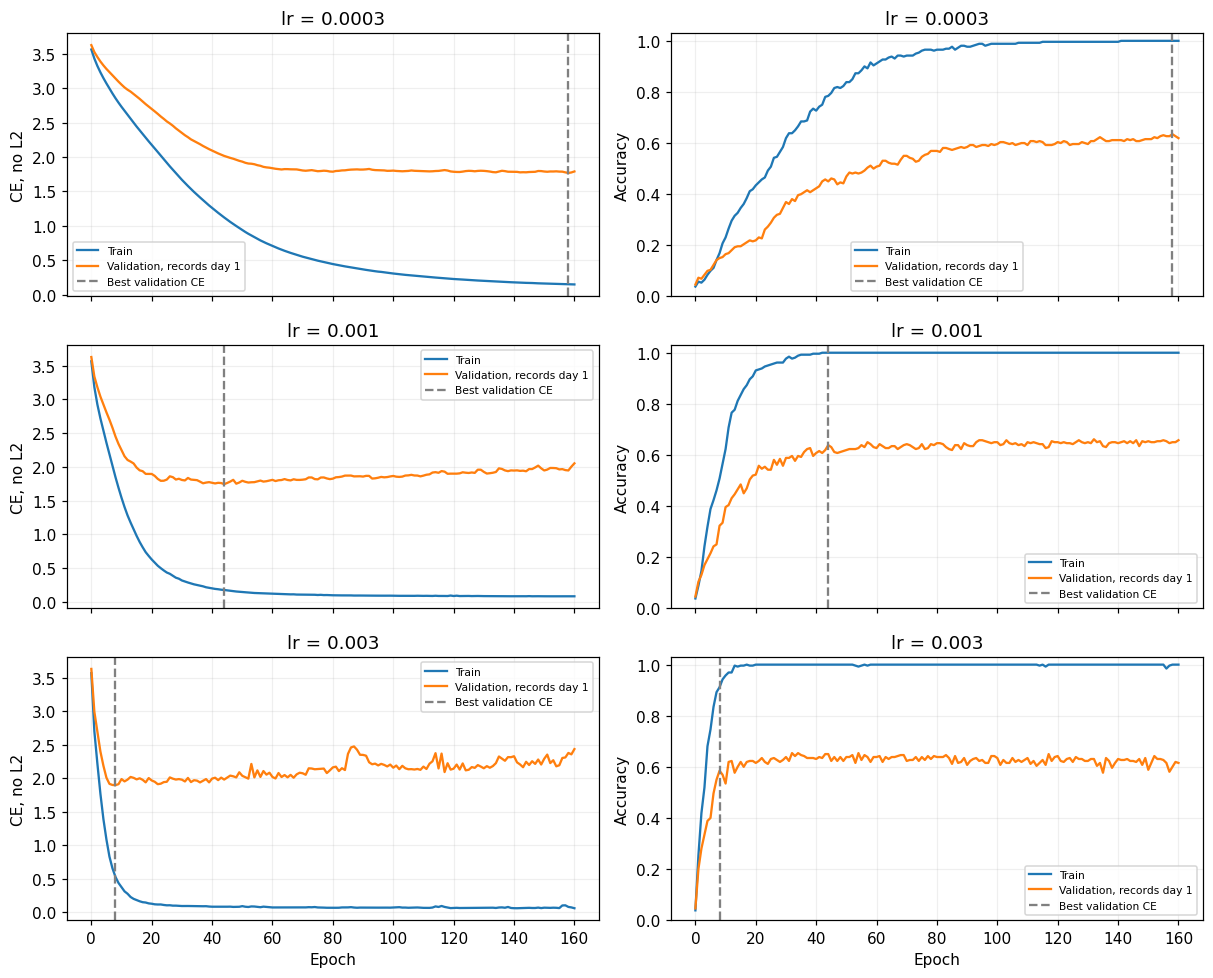

In [11]:
# Фиксируем настройки до новых экспериментов; второй день здесь не используется.
sizes = [96, 64, 32, K]
REFERENCE = {"lr": 1e-3, "l2": 1e-2, "epochs": 44, "dropout": 0.0}
EXPERIMENT_EPOCHS = 160
learning_rates = (3e-4, 1e-3, 3e-3)
lr_runs = []
for lr in learning_rates:
    params, history, epoch = train_network(X_train, y_train, sizes, lr=lr, l2=0.01,
        epochs=EXPERIMENT_EPOCHS, validation=(X_val, y_val), patience=None)
    lr_runs.append({"lr": lr, "params": params, "history": history, "epoch": epoch,
                    "metrics": evaluate(X_val, y_val, params)})
table(["Learning rate", "Лучшая эпоха по CE", "Лучшая val CE", "Accuracy checkpoint", "CE на 160-й", "Accuracy на 160-й"],
      [[r["lr"], r["epoch"], f'{r["metrics"]["ce"]:.4f}', f'{r["metrics"]["accuracy"]:.2%}',
        f'{r["history"]["val_ce"][-1]:.4f}', f'{r["history"]["val_accuracy"][-1]:.2%}'] for r in lr_runs])

# Сопоставляем кривые по одному значению lr в строке; масштаб accuracy одинаковый.
fig, axes = plt.subplots(3, 2, figsize=(11, 9), sharex=True)
for row, run in enumerate(lr_runs):
    h = run["history"]
    for col, metric in enumerate(["ce", "accuracy"]):
        ax = axes[row, col]
        for split, label in [("train", "Train"), ("val", "Validation, records day 1")]:
            ax.plot(h["epoch"], h[f"{split}_{metric}"], label=label)
        ax.axvline(run["epoch"], color="gray", linestyle="--", label="Best validation CE")
        ax.set_title(f'lr = {run["lr"]:g}')
        ax.set_ylabel("CE, no L2" if metric == "ce" else "Accuracy")
        if metric == "accuracy": ax.set_ylim(0, 1.03)
        ax.grid(alpha=.2)
        ax.legend(fontsize=7)
for ax in axes[-1]: ax.set_xlabel("Epoch")
fig.tight_layout()
plt.show()

Маленький learning rate обычно даёт более медленное снижение потерь; большой быстрее проходит начальный участок, но может сильнее колебаться и раньше переобучаться. Сравнивать только обучающую точность неправильно: при приближении train accuracy к единице валидационная CE может расти. Результат зависит от числа эпох, поэтому сравнение проведено при общем бюджете и с отдельным указанием checkpoint.

### Dropout и его влияние
Сравниваем $p=0$, $p=0.25$ и $p=0.5$ при `lr=0.001`, `L2=0.01` и том же бюджете 160 эпох. При $p=0$ повторно используем уже выполненный опыт. Раздельные генераторы для перемешивания и масок обеспечивают одинаковые начальные веса и одинаковый порядок обучающих батчей.

На каждой эпохе train и validation оцениваются **в режиме inference**, поэтому разрыв между кривыми не возникает из-за разных режимов Dropout. Сильный Dropout может уменьшить переобучение, но одновременно затруднить обучение; рост качества заранее не предполагается.

| Dropout p | Лучшая эпоха | Лучшая val CE | Accuracy checkpoint | Train accuracy, 160 | Val accuracy, 160 | Разрыв, п.п. |
| --- | --- | --- | --- | --- | --- | --- |
| 0.0 | 44 | 1.7432 | 63.85% | 100.00% | 65.77% | 34.23 |
| 0.25 | 61 | 1.7409 | 62.31% | 100.00% | 64.62% | 35.38 |
| 0.5 | 76 | 2.0562 | 56.54% | 98.46% | 64.23% | 34.23 |

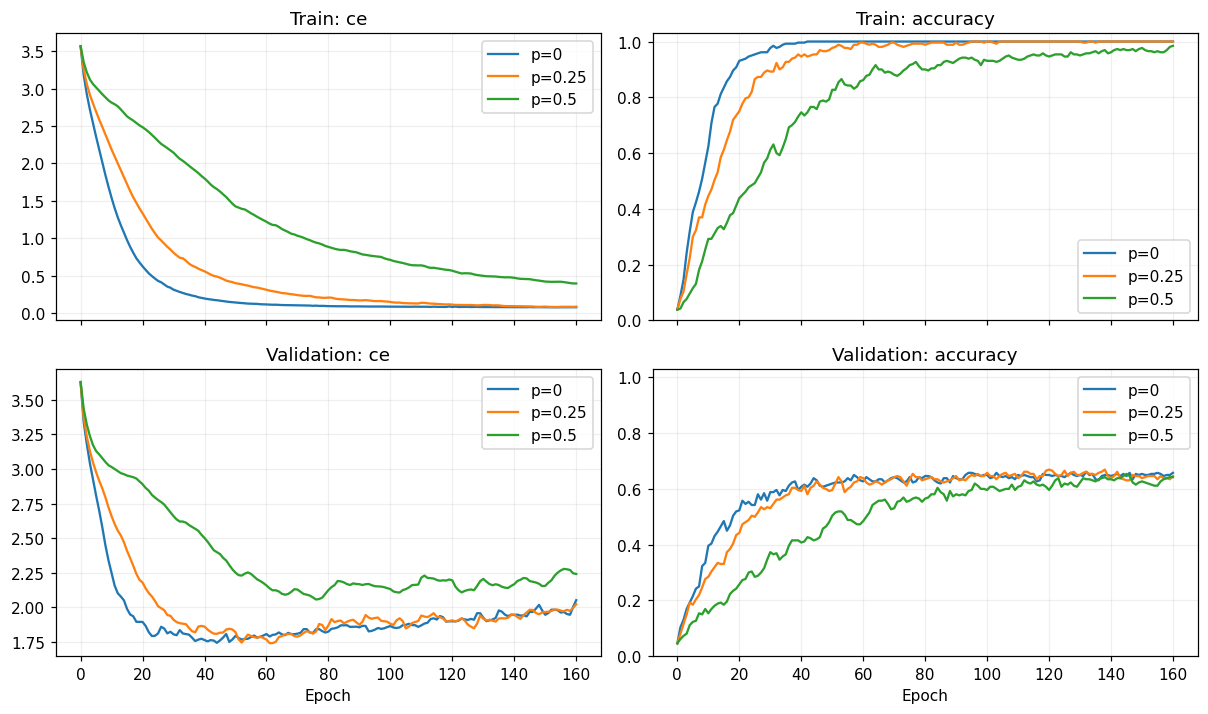

| Dropout p | Изменение лучшей val CE к p=0 | Изменение accuracy checkpoint, п.п. |
| --- | --- | --- |
| 0.25 | -0.0023 | -1.54 |
| 0.5 | +0.3130 | -7.31 |

В этом запуске p=0.25 изменил лучшую val CE всего на **-0.0023**, а accuracy соответствующего checkpoint — на **-1.54 п.п.** При p=0.5 лучшая CE стала хуже на **+0.3130**. Dropout замедлил обучение; на этих записях убедительного улучшения качества не получено. Меньшая CE не обязательно соответствует большей accuracy: CE учитывает вероятности всех ответов, accuracy — только класс с наибольшим логитом. Один seed и одно разбиение не позволяют считать малую разницу устойчивой. Эти опыты не подтверждают улучшение переноса на новый день.

In [12]:
# Меняем только вероятность отключения скрытых активаций, не масштабирование или разбиение.
base_run = next(r for r in lr_runs if r["lr"] == 1e-3)
dropout_runs = [{"p": 0., **{k: base_run[k] for k in ("params", "history", "epoch", "metrics")}}]
for p in (0.25, 0.5):
    params, history, epoch = train_network(X_train, y_train, sizes, lr=1e-3, l2=0.01,
        epochs=EXPERIMENT_EPOCHS, validation=(X_val, y_val), patience=None, dropout=p)
    dropout_runs.append({"p": p, "params": params, "history": history, "epoch": epoch,
                         "metrics": evaluate(X_val, y_val, params)})
table(["Dropout p", "Лучшая эпоха", "Лучшая val CE", "Accuracy checkpoint", "Train accuracy, 160", "Val accuracy, 160", "Разрыв, п.п."],
      [[r["p"], r["epoch"], f'{r["metrics"]["ce"]:.4f}', f'{r["metrics"]["accuracy"]:.2%}',
        f'{r["history"]["train_accuracy"][-1]:.2%}', f'{r["history"]["val_accuracy"][-1]:.2%}',
        f'{100*(r["history"]["train_accuracy"][-1]-r["history"]["val_accuracy"][-1]):.2f}'] for r in dropout_runs])
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6), sharex=True)
for run in dropout_runs:
    h = run["history"]
    for row, split in enumerate(["train", "val"]):
        for col, metric in enumerate(["ce", "accuracy"]):
            ax = axes[row, col]
            ax.plot(h["epoch"], h[f"{split}_{metric}"], label=f'p={run["p"]:g}')
            ax.set_title(f'{"Train" if split == "train" else "Validation"}: {metric}')
            ax.grid(alpha=.2)
            ax.legend()
            if metric == "accuracy": ax.set_ylim(0, 1.03)
for ax in axes[-1]: ax.set_xlabel("Epoch")
fig.tight_layout()
plt.show()

# Формируем вывод из измеренного эффекта, не предполагая, что Dropout обязан улучшить accuracy.
base = dropout_runs[0]
effect_rows = []
for run in dropout_runs[1:]:
    delta_ce = run["metrics"]["ce"] - base["metrics"]["ce"]
    delta_acc = 100 * (run["metrics"]["accuracy"] - base["metrics"]["accuracy"])
    effect_rows.append([run["p"], f"{delta_ce:+.4f}", f"{delta_acc:+.2f}"])
table(["Dropout p", "Изменение лучшей val CE к p=0", "Изменение accuracy checkpoint, п.п."], effect_rows)
display(Markdown(f"В этом запуске p=0.25 изменил лучшую val CE всего на **{dropout_runs[1]['metrics']['ce']-base['metrics']['ce']:+.4f}**, "
    f"а accuracy соответствующего checkpoint — на **{100*(dropout_runs[1]['metrics']['accuracy']-base['metrics']['accuracy']):+.2f} п.п.** "
    f"При p=0.5 лучшая CE стала хуже на **{dropout_runs[2]['metrics']['ce']-base['metrics']['ce']:+.4f}**. "
    "Dropout замедлил обучение; на этих записях убедительного улучшения качества не получено. "
    "Меньшая CE не обязательно соответствует большей accuracy: CE учитывает вероятности всех ответов, "
    "accuracy — только класс с наибольшим логитом. Один seed и одно разбиение не позволяют считать малую разницу устойчивой. "
    "Эти опыты не подтверждают улучшение переноса на новый день."))

## 4. Две поломки той же сети
В обоих опытах используем **тот же код** `forward`, `loss_and_gradients`, `adam_step`, `train_network`, то же разбиение, масштабирование и архитектуру. Меняем только одну настройку относительно исправного обучения:

1. **Слишком большой learning rate:** Adam с `lr=1.0`, в 1000 раз больше базового. Адаптивность Adam не устраняет влияние общего множителя шага.
2. **Все веса и смещения равны нулю:** `initialization="zeros"`, базовый `lr=0.001`.

Выполняем по 80 эпох без ранней остановки и анализируем именно последние параметры, чтобы ранняя остановка не скрывала поломку. Добавляем исходную эпоху 0, максимум нормы градиента за батчи эпохи и долю скрытых нейронов, не активных ни на одном обучающем окне. Численных ограничителей, clipping или перезапуска в этих опытах нет. Если началось бы переполнение, проверка конечности остановила бы расчёт вместо выдачи ненадёжных метрик.

| Опыт | CE после 1 эпохи | Макс. val CE | Val CE, последняя | Accuracy, последняя | Неактивных скрытых, последняя |
| --- | --- | --- | --- | --- | --- |
| Normal | 3.339 | 3.628 | 1.8245 | 64.62% | 0.0% |
| Too large lr = 1.0 | 7.598 | 7.598 | 3.3830 | 3.85% | 99.0% |
| All weights zero | 3.258 | 3.258 | 3.2582 | 3.85% | 100.0% |

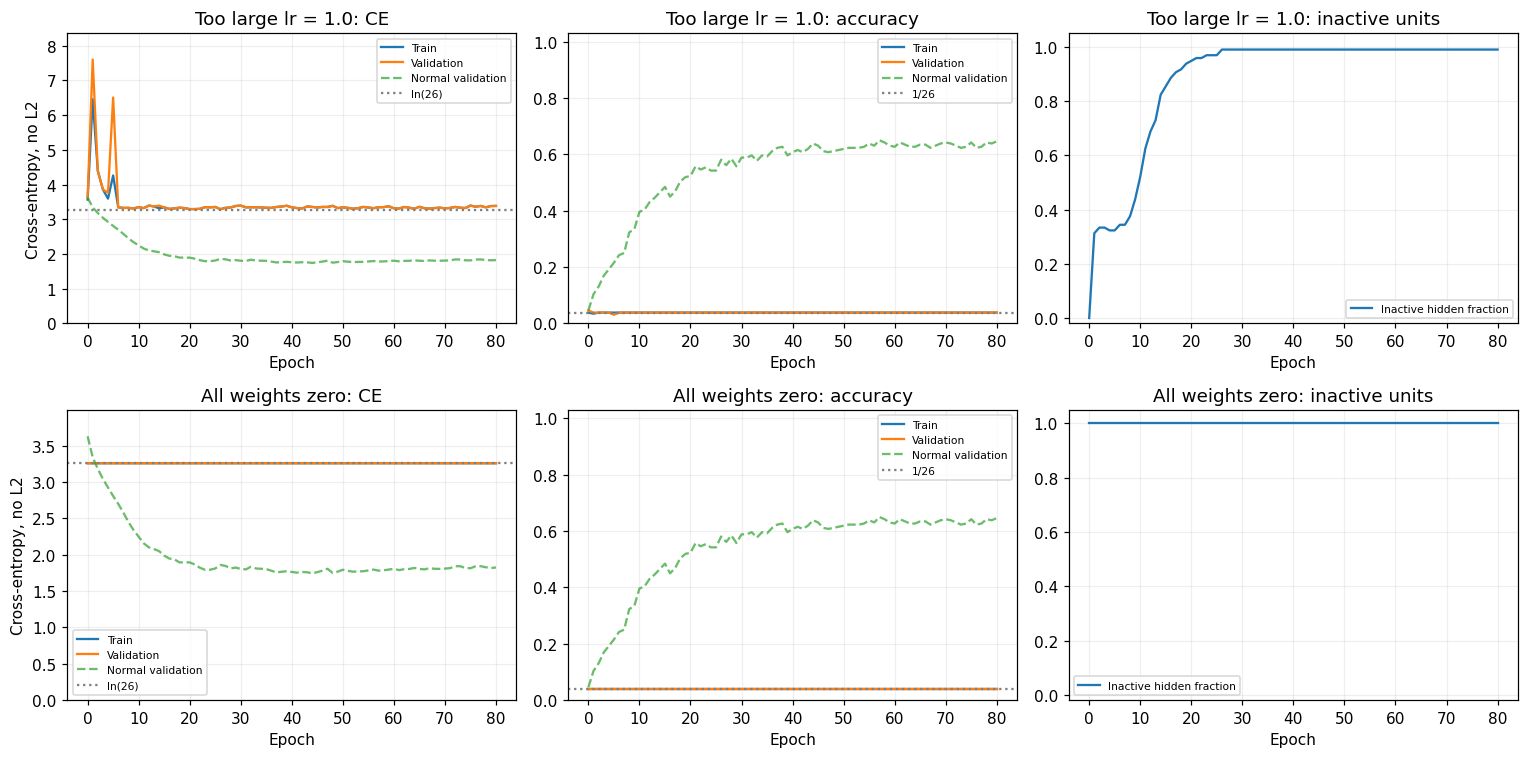

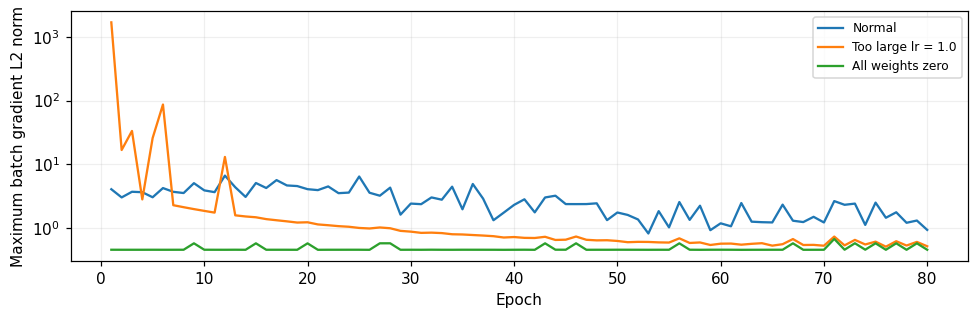

In [13]:
# Исправный контроль и две намеренные поломки отличаются ровно указанной настройкой.
failure_configs = [
    ("Normal", {"lr": 1e-3, "initialization": "he"}),
    ("Too large lr = 1.0", {"lr": 1., "initialization": "he"}),
    ("All weights zero", {"lr": 1e-3, "initialization": "zeros"}),
]
failure_runs = []
for label, config in failure_configs:
    params, history, epoch = train_network(X_train, y_train, sizes, **config,
        l2=0.01, epochs=80, validation=(X_val, y_val), patience=None, return_best=False)
    failure_runs.append({"label": label, "params": params, "history": history,
                         "metrics": evaluate(X_val, y_val, params)})
table(["Опыт", "CE после 1 эпохи", "Макс. val CE", "Val CE, последняя", "Accuracy, последняя", "Неактивных скрытых, последняя"],
      [[r["label"], f'{r["history"]["val_ce"][1]:.3f}', f'{max(r["history"]["val_ce"]):.3f}',
        f'{r["metrics"]["ce"]:.4f}', f'{r["metrics"]["accuracy"]:.2%}',
        f'{r["history"]["dead_hidden"][-1]:.1%}'] for r in failure_runs])

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for row, run in enumerate(failure_runs[1:]):
    h = run["history"]
    for split, label in [("train", "Train"), ("val", "Validation")]:
        axes[row, 0].plot(h["epoch"], h[f"{split}_ce"], label=label)
        axes[row, 1].plot(h["epoch"], h[f"{split}_accuracy"], label=label)
    control = failure_runs[0]["history"]
    axes[row, 0].plot(control["epoch"], control["val_ce"], "--", label="Normal validation", alpha=.7)
    axes[row, 1].plot(control["epoch"], control["val_accuracy"], "--", label="Normal validation", alpha=.7)
    axes[row, 0].axhline(np.log(K), color="gray", linestyle=":", label="ln(26)")
    axes[row, 1].axhline(1/K, color="gray", linestyle=":", label="1/26")
    axes[row, 0].set_ylim(0, 1.1 * max(h["train_ce"] + h["val_ce"] + control["val_ce"]))
    axes[row, 0].set_ylabel("Cross-entropy, no L2")
    axes[row, 0].set_title(run["label"] + ": CE")
    axes[row, 1].set_title(run["label"] + ": accuracy")
    axes[row, 1].set_ylim(0, 1.03)
    axes[row, 2].plot(h["epoch"], h["dead_hidden"], label="Inactive hidden fraction")
    axes[row, 2].set_ylim(-.02, 1.05)
    axes[row, 2].set_title(run["label"] + ": inactive units")
    for ax in axes[row]:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=.2)
        ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

# Диагностируем нулевую инициализацию: веса и скрытые смещения так и остались нулевыми.
zero_params = failure_runs[2]["params"]
for name, value in zero_params.items():
    if name != "b3": assert np.count_nonzero(value) == 0
zero_logits, _ = forward(X_val, zero_params)
assert np.allclose(zero_logits, np.broadcast_to(zero_logits[0], zero_logits.shape))
assert np.isclose(failure_runs[2]["metrics"]["accuracy"], 1/K)

# Показываем величину градиента, в том числе его возможные резкие скачки при большом шаге.
fig, ax = plt.subplots(figsize=(9, 3))
for run in failure_runs:
    h = run["history"]
    ax.plot(h["epoch"][1:], h["grad_norm"][1:], label=run["label"])
ax.set_yscale("symlog", linthresh=1e-3)
ax.set_xlabel("Epoch")
ax.set_ylabel("Maximum batch gradient L2 norm")
ax.legend(fontsize=8)
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

### Что именно сломалось
**Слишком большой шаг.** Изменения весов слишком велики относительно полезного направления локального градиента. Модель перескакивает области с низкой потерей; логиты и CE могут резко увеличиваться. После сильных обновлений часть ReLU может оказаться неактивной для всех обучающих окон, и такие пути получают нулевой градиент от данных. На графиках отдельно показана фактически измеренная доля неактивных нейронов: большой learning rate не обязан выключать все ReLU или обязательно давать `NaN`. Даже устойчивый softmax защищает только от переполнения при вычислении вероятностей и не делает шаг оптимизатора разумным. L2 может постепенно уменьшать веса, но не исправляет автоматически неверный масштаб шага.

**Нулевая инициализация.** У всех скрытых нейронов одинаковые параметры; симметрия не нарушена. В данной ReLU-сети ситуация ещё жёстче: все скрытые активации нулевые, а производная ReLU в нуле принята равной нулю. Поэтому $\nabla W_3=A_2^\top D_3=0$, скрытые градиенты также нулевые; L2 от нулевых весов равен нулю. Изменяться могут только выходные смещения `b3` из-за несбалансированных мини-батчей. В результате прогноз не зависит от сигнала, а accuracy на сбалансированном контроле равна $1/26\approx0.03846$. CE остаётся около $\ln26\approx3.258$ и может слегка превышать её из-за колебаний смещений. Это проверено утверждениями в коде, а не только формой кривой.

In [14]:
# Подкрепляем объяснение большого шага наблюдаемыми величинами этого запуска.
normal, high, zero = failure_runs
h = high["history"]
display(Markdown(f"При lr=1.0 максимальная валидационная CE составила **{max(h['val_ce']):.2f}**, "
    f"а на последней эпохе — **{high['metrics']['ce']:.4f}** при accuracy **{high['metrics']['accuracy']:.2%}**. "
    f"В конце неактивны **{h['dead_hidden'][-1]:.1%}** скрытых нейронов на обучающих окнах. "
    f"При нормальном шаге итоговая валидационная CE — **{normal['metrics']['ce']:.4f}**, "
    f"accuracy — **{normal['metrics']['accuracy']:.2%}**. Эти числа характеризуют именно проведённый опыт; "
    "неактивность нейрона на текущих данных сама по себе не доказывает, что он останется таким при любых будущих входах."))

При lr=1.0 максимальная валидационная CE составила **7.60**, а на последней эпохе — **3.3830** при accuracy **3.85%**. В конце неактивны **99.0%** скрытых нейронов на обучающих окнах. При нормальном шаге итоговая валидационная CE — **1.8245**, accuracy — **64.62%**. Эти числа характеризуют именно проведённый опыт; неактивность нейрона на текущих данных сама по себе не доказывает, что он останется таким при любых будущих входах.

## 5. Три схемы оценки и ответ заказчику
В каждой схеме используется **одна зафиксированная базовая конфигурация** из начала пункта 3 и собственный scaler, обученный только на текущем train. Ни число эпох, ни seed, ни Dropout не выбираются по результату этой таблицы.

| Схема | Обучение | Контроль | Что измеряем |
|---|---|---|---|
| Случайно по нажатиям, день 1 | По 10 случайных нажатий каждой буквы | Оставшиеся 10 нажатий | Условно похожие соседние нажатия; записи пересекаются |
| По записям внутри дня 1 | По одной полной записи каждой буквы | Вторая запись каждой буквы | Перенос на другую запись того же дня |
| День 1 → день 2 | Все 520 окон дня 1 | Все 520 окон дня 2 | Перенос между днями и повторным надеванием браслета |

Для первых двух схем дополнительно меняем train и контроль местами: **два взаимно обратных разбиения**, каждое 260/260. Каждое окно дня 1 получает ровно один out-of-fold прогноз. Основное число в таблице — accuracy по всем 520 таким прогнозам; рядом приведены результаты каждого разбиения. В случайной схеме считаем число общих записей, чтобы показать нарушение независимости. Для групповой схемы проверяем отсутствие пересечения записей.

**Ограничение честности оценки:** исходная базовая конфигурация уже выбиралась по одном из групповых разбиений в предыдущей версии. Поэтому её результат и объединённая сводка могут быть оптимистичны от выбора настроек, хотя утечки соседних нажатий нет. Это диагностическая оценка на имеющихся данных, а не новый независимый сертификат прохождения порога. Самостоятельно выделить полноценные train/validation/test с наличием всех букв и непересекающихся записей внутри одного дня невозможно: есть лишь две записи на букву. Нужны дополнительные записи или новый день.

| Схема | Train окон | Контрольных прогнозов | Accuracy по разбиениям | Общая accuracy | Macro-F1 | Общих записей |
| --- | --- | --- | --- | --- | --- | --- |
| Случайно по нажатиям, день 1 | 260 × 2 | 520 | 78.46%; 78.46% | 78.46% | 0.7817 | 52; 52 |
| По записям, день 1 | 260 × 2 | 520 | 63.85%; 61.15% | 62.50% | 0.5923 | 0; 0 |
| День 1 → день 2 | 520 | 520 | 19.04% | 19.04% | 0.1360 | 0 |

Порог по записям (два разбиения): 0.6250 >= 0.60 — выполнен.
Шанс равномерного угадывания: 0.03846


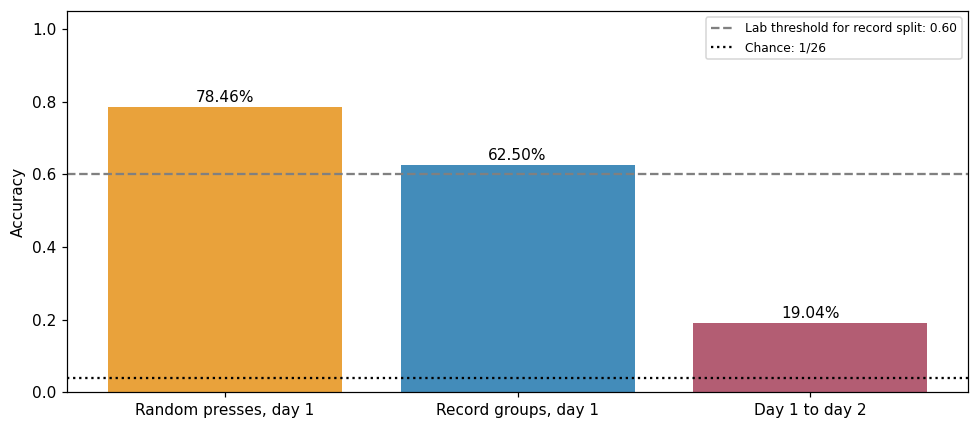

In [15]:
def fit_and_score_split(train_idx, control_idx):
    # Для каждого нового разбиения заново обучаем scaler и сеть, используя только train.
    scaler = fit_scaler(X[train_idx])
    train_x = transform_scaler(X[train_idx], scaler)
    control_x = transform_scaler(X[control_idx], scaler)
    params, history, _ = train_network(train_x, y[train_idx], sizes, **REFERENCE, validation=None)
    logits, _ = forward(control_x, params)
    pred = logits.argmax(axis=1)
    result = classification_metrics(y[control_idx], pred, K)
    result["ce"] = cross_entropy(logits, y[control_idx])
    return {"params": params, "scaler": scaler, "history": history, "pred": pred,
            "logits": logits, "metrics": result, "train": train_idx, "control": control_idx,
            "shared_groups": len(set(recording[train_idx]) & set(recording[control_idx]))}

# Случайное разбиение нажатий стратифицируем вручную, без sklearn.model_selection.
random_rng = np.random.default_rng(2026)
random_a, random_b = [], []
for cls in range(K):
    indices = random_rng.permutation(np.flatnonzero((day == 1) & (y == cls)))
    random_a.extend(indices[:10])
    random_b.extend(indices[10:])
random_a, random_b = np.sort(random_a), np.sort(random_b)
random_folds = [fit_and_score_split(random_a, random_b), fit_and_score_split(random_b, random_a)]
group_folds = [fit_and_score_split(idx_train, idx_val), fit_and_score_split(idx_val, idx_train)]
for fold in group_folds: assert fold["shared_groups"] == 0


def collect_oof(folds):
    # Объединяем только отложенные прогнозы; каждое окно первого дня встречается один раз.
    indices = np.concatenate([f["control"] for f in folds])
    pred = np.concatenate([f["pred"] for f in folds])
    assert len(indices) == len(np.unique(indices)) == len(idx_dev)
    assert set(indices) == set(idx_dev)
    return classification_metrics(y[indices], pred, K)

random_oof = collect_oof(random_folds)
group_oof = collect_oof(group_folds)
# Второй день используется только для воспроизведения исходной фиксированной базовой модели.
cross_day = fit_and_score_split(idx_dev, idx_test)
assert cross_day["shared_groups"] == 0
mlp_test = cross_day["metrics"]
mlp_pred = cross_day["pred"]
mlp_logits = cross_day["logits"]
final_params = cross_day["params"]
X_test = transform_scaler(X[idx_test], cross_day["scaler"])
y_test = y[idx_test]
comparison_rows = []
for name, folds, result in [("Случайно по нажатиям, день 1", random_folds, random_oof),
                            ("По записям, день 1", group_folds, group_oof)]:
    comparison_rows.append([name, "260 × 2", 520,
        "; ".join(f'{f["metrics"]["accuracy"]:.2%}' for f in folds),
        f'{result["accuracy"]:.2%}', f'{result["macro_f1"]:.4f}',
        "; ".join(str(f["shared_groups"]) for f in folds)])
comparison_rows.append(["День 1 → день 2", 520, 520, f'{mlp_test["accuracy"]:.2%}',
    f'{mlp_test["accuracy"]:.2%}', f'{mlp_test["macro_f1"]:.4f}', 0])
table(["Схема", "Train окон", "Контрольных прогнозов", "Accuracy по разбиениям", "Общая accuracy", "Macro-F1", "Общих записей"], comparison_rows)
threshold_met = group_oof["accuracy"] >= .60
print(f'Порог по записям (два разбиения): {group_oof["accuracy"]:.4f} >= 0.60 — {"выполнен" if threshold_met else "не выполнен"}.')
print("Шанс равномерного угадывания:", round(1/K, 5))

# На графике сопоставляем три реально полученные оценки; линия 0.60 относится к групповой схеме.
fig, ax = plt.subplots(figsize=(9, 4))
values = [random_oof["accuracy"], group_oof["accuracy"], mlp_test["accuracy"]]
bars = ax.bar(["Random presses, day 1", "Record groups, day 1", "Day 1 to day 2"], values,
              color=["#e9a23b", "#438cba", "#b35d73"])
ax.axhline(.60, color="gray", linestyle="--", label="Lab threshold for record split: 0.60")
ax.axhline(1/K, color="black", linestyle=":", label="Chance: 1/26")
for bar, value in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, value+.015, f"{value:.2%}", ha="center")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Почему числа различаются
**Случайно по нажатиям:** в train и контроль попадают соседние окна одной записи — одной буквы, руки и положения браслета. Модель использует общие особенности записи; это упрощает задачу. Такая оценка отвечает на вопрос о похожих повторах внутри уже наблюдавшихся условий и не подходит для решения о выпуске.

**По записям внутри дня:** соседние нажатия одной записи не пересекают границу. Качество отражает более сложный перенос на другую запись, но положение браслета и день ещё общие. Это схема, к которой относится учебный порог 0,60.

**Между днями:** к различиям записей добавляются изменения условий измерения, включая снятие и повторное надевание браслета. Это сдвиг распределения. Его нельзя однозначно приписать только смещению электродов. В междневном опыте обучающих окон даже больше, чем в каждом внутридневном разбиении, поэтому разница чисел не является чистой причинной оценкой одного фактора; она всё же демонстрирует практическую проблему переноса.

Упорядочение метрик не является математической гарантией для любого набора данных. Выводы ниже опираются на фактически полученную таблицу, а не на предположение, что случайное разбиение всегда обязано давать максимальное число.

### Разрешённая линейная точка отсчёта
Логистическая регрессия остаётся единственной готовой обучаемой моделью. Для воспроизведения исходного сравнения значение `C` выбирается по той же групповой валидации первого дня; масштабирование, CE и метрики считаются вручную.

In [16]:
# Единственное исключение из запрета готового обучения — линейная точка отсчёта.
baseline_runs = []
for c in (0.01, 0.1, 1.0, 10.0):
    model = LogisticRegression(C=c, solver="lbfgs", max_iter=3000, tol=1e-7)
    model.fit(X_train, y_train)
    assert np.array_equal(model.classes_, np.arange(K))
    logits = model.decision_function(X_val)
    metrics = classification_metrics(y_val, logits.argmax(axis=1), K)
    baseline_runs.append({"C": c, "ce": cross_entropy(logits, y_val), "metrics": metrics})
best_baseline = min(baseline_runs, key=lambda r: r["ce"])
table(["C", "Val CE", "Val accuracy", "Val macro-F1"],
      [[r["C"], f'{r["ce"]:.4f}', f'{r["metrics"]["accuracy"]:.2%}', f'{r["metrics"]["macro_f1"]:.4f}'] for r in baseline_runs])
print("Версия scikit-learn:", sklearn.__version__, "выбрано C =", best_baseline["C"])


# Переобучаем выбранную линейную модель на всём первом дне, не меняя её по дню 2.
X_dev = transform_scaler(X[idx_dev], cross_day["scaler"])
final_baseline = LogisticRegression(C=best_baseline["C"], solver="lbfgs", max_iter=3000, tol=1e-7)
final_baseline.fit(X_dev, y[idx_dev])
assert np.array_equal(final_baseline.classes_, np.arange(K))
linear_logits = final_baseline.decision_function(X_test)
linear_pred = linear_logits.argmax(axis=1)
linear_test = classification_metrics(y_test, linear_pred, K)
linear_test["ce"] = cross_entropy(linear_logits, y_test)
table(["Модель", "День 2 accuracy", "День 2 CE", "День 2 macro-F1"],
      [[name, f'{result["accuracy"]:.2%}', f'{result["ce"]:.4f}', f'{result["macro_f1"]:.4f}']
       for name, result in [("MLP с нуля", mlp_test), ("Логистическая регрессия", linear_test)]])

| C | Val CE | Val accuracy | Val macro-F1 |
| --- | --- | --- | --- |
| 0.01 | 2.3104 | 64.62% | 0.6175 |
| 0.1 | 2.1236 | 66.15% | 0.6325 |
| 1.0 | 2.4684 | 65.77% | 0.6227 |
| 10.0 | 3.1043 | 65.77% | 0.6242 |

Версия scikit-learn: 1.7.2 выбрано C = 0.1


| Модель | День 2 accuracy | День 2 CE | День 2 macro-F1 |
| --- | --- | --- | --- |
| MLP с нуля | 19.04% | 5.4419 | 0.1360 |
| Логистическая регрессия | 15.77% | 3.5213 | 0.0999 |

### Неопределённость оценки
Десять соседних нажатий не считаем десятью независимыми испытаниями. Для ориентировочного 95%-интервала accuracy используем **стратифицированный кластерный bootstrap по записям** дня 2: внутри каждой буквы выбираем с возвращением две целые записи и усредняем их accuracy. Обе модели получают одни и те же bootstrap-выборки; это также даёт парный интервал разности accuracy MLP − линейная модель.

Интервалы условны: один человек, один тестовый день и всего две записи на букву. Они не отражают неопределённость переноса на других людей или будущие дни; корреляцию между записями одного дня этим методом устранить нельзя. В каждом классе сохранено одинаковое число нажатий.


In [17]:
def cluster_bootstrap(targets, prediction_a, prediction_b, groups, n_classes, repetitions=5000, seed=2026):
    # Ресэмплируем целые записи внутри класса, сохраняя парность сравнения двух моделей.
    rng = np.random.default_rng(seed)
    group_scores = []
    for cls in range(n_classes):
        ids = np.unique(groups[targets == cls])
        assert len(ids) == 2
        rows = []
        for group in ids:
            mask = groups == group
            assert len(np.unique(targets[mask])) == 1 and mask.sum() == 10
            rows.append([np.mean(prediction_a[mask] == targets[mask]),
                         np.mean(prediction_b[mask] == targets[mask])])
        group_scores.append(rows)
    group_scores = np.array(group_scores)
    picks = rng.integers(0, 2, size=(repetitions, n_classes, 2))
    sampled = group_scores[np.arange(n_classes)[None, :, None], picks]
    estimates = sampled.mean(axis=(1, 2))
    return np.quantile(estimates[:, 0], [0.025, 0.975]), np.quantile(estimates[:, 1], [0.025, 0.975]), np.quantile(estimates[:, 0] - estimates[:, 1], [0.025, 0.975])

ci_mlp, ci_linear, ci_difference = cluster_bootstrap(y_test, mlp_pred, linear_pred, recording[idx_test], K)
table(["Показатель", "Оценка", "Условный 95% bootstrap-интервал"],
      [["Accuracy MLP", f'{mlp_test["accuracy"]:.2%}', f"[{ci_mlp[0]:.2%}; {ci_mlp[1]:.2%}]"],
       ["Accuracy линейной модели", f'{linear_test["accuracy"]:.2%}', f"[{ci_linear[0]:.2%}; {ci_linear[1]:.2%}]"],
       ["MLP − линейная модель, п.п.", f'{100*(mlp_test["accuracy"]-linear_test["accuracy"]):.2f}',
        f"[{100*ci_difference[0]:.2f}; {100*ci_difference[1]:.2f}]"]])


| Показатель | Оценка | Условный 95% bootstrap-интервал |
| --- | --- | --- |
| Accuracy MLP | 19.04% | [15.96%; 22.12%] |
| Accuracy линейной модели | 15.77% | [12.88%; 18.65%] |
| MLP − линейная модель, п.п. | 3.27 | [1.35; 5.19] |

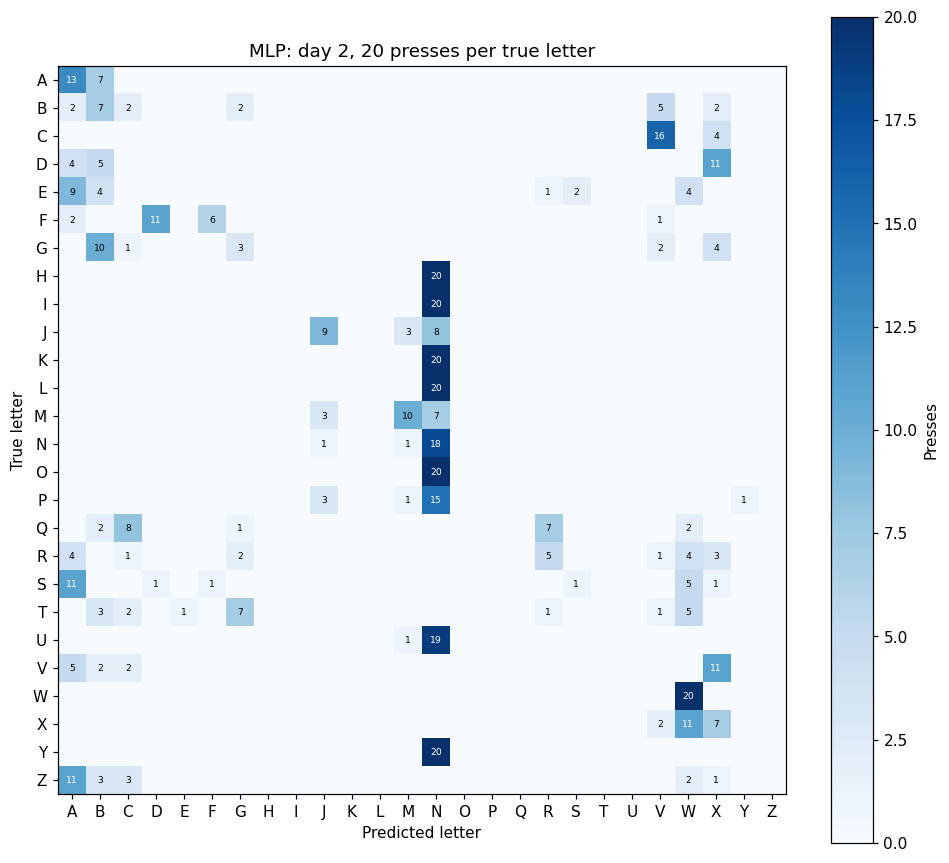

| Буква | Объектов | Precision MLP | Recall MLP | F1 MLP |
| --- | --- | --- | --- | --- |
| A | 20 | 0.213 | 0.650 | 0.321 |
| B | 20 | 0.163 | 0.350 | 0.222 |
| C | 20 | 0.000 | 0.000 | 0.000 |
| D | 20 | 0.000 | 0.000 | 0.000 |
| E | 20 | 0.000 | 0.000 | 0.000 |
| F | 20 | 0.857 | 0.300 | 0.444 |
| G | 20 | 0.200 | 0.150 | 0.171 |
| H | 20 | 0.000 | 0.000 | 0.000 |
| I | 20 | 0.000 | 0.000 | 0.000 |
| J | 20 | 0.562 | 0.450 | 0.500 |
| K | 20 | 0.000 | 0.000 | 0.000 |
| L | 20 | 0.000 | 0.000 | 0.000 |
| M | 20 | 0.625 | 0.500 | 0.556 |
| N | 20 | 0.096 | 0.900 | 0.174 |
| O | 20 | 0.000 | 0.000 | 0.000 |
| P | 20 | 0.000 | 0.000 | 0.000 |
| Q | 20 | 0.000 | 0.000 | 0.000 |
| R | 20 | 0.357 | 0.250 | 0.294 |
| S | 20 | 0.333 | 0.050 | 0.087 |
| T | 20 | 0.000 | 0.000 | 0.000 |
| U | 20 | 0.000 | 0.000 | 0.000 |
| V | 20 | 0.000 | 0.000 | 0.000 |
| W | 20 | 0.377 | 1.000 | 0.548 |
| X | 20 | 0.159 | 0.350 | 0.219 |
| Y | 20 | 0.000 | 0.000 | 0.000 |
| Z | 20 | 0.000 | 0.000 | 0.000 |

| Истинная буква | Предсказана | Ошибочных нажатий |
| --- | --- | --- |
| H | N | 20 |
| I | N | 20 |
| K | N | 20 |
| L | N | 20 |
| O | N | 20 |
| Y | N | 20 |
| U | N | 19 |
| C | V | 16 |
| P | N | 15 |
| D | X | 11 |

In [18]:
# Разбираем ошибки зафиксированной MLP по классам, не используя их для дообучения.
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(mlp_test["cm"], cmap="Blues", vmin=0, vmax=20)
ax.set_xticks(np.arange(K), classes)
ax.set_yticks(np.arange(K), classes)
ax.set_xlabel("Predicted letter")
ax.set_ylabel("True letter")
ax.set_title("MLP: day 2, 20 presses per true letter")
for i in range(K):
    for j in range(K):
        value = mlp_test["cm"][i, j]
        if value:
            ax.text(j, i, str(value), ha="center", va="center", fontsize=6,
                    color="white" if value > 10 else "black")
fig.colorbar(im, ax=ax, label="Presses")
fig.tight_layout()
plt.show()

table(["Буква", "Объектов", "Precision MLP", "Recall MLP", "F1 MLP"],
      [[cls, int(np.sum(y_test == i)), f'{mlp_test["precision"][i]:.3f}',
        f'{mlp_test["recall"][i]:.3f}', f'{mlp_test["f1"][i]:.3f}'] for i, cls in enumerate(classes)])
confusions = [(int(mlp_test["cm"][i, j]), classes[i], classes[j])
              for i in range(K) for j in range(K) if i != j and mlp_test["cm"][i, j] > 0]
confusions.sort(key=lambda item: (-item[0], item[1], item[2]))
table(["Истинная буква", "Предсказана", "Ошибочных нажатий"], [[a, b, n] for n, a, b in confusions[:10]])


### Вывод для заказчика
Порог лабораторной работы проверяем отдельно от вопроса о выпуске устройства. Высокое внутридневное число не заменяет проверку снятия и повторного надевания браслета, новых людей, непрерывного сигнала и реального набора текста.

In [21]:
# Итоговый текст использует только фактически рассчитанные значения и явно указывает статус контроля.
status = "выполнен" if threshold_met else "не выполнен"
best_dropout = min(dropout_runs, key=lambda r: r["metrics"]["ce"])
display(Markdown(f"""
**Если коротко по пунктам, то:**
**Пункты 1–2 выполнены:** 96 самостоятельно посчитанных признаков, собственные scaler, forward, softmax, CE, backward и Adam. Относительная ошибка градиента рабочей сети — **{working_error:.2e}**, с зафиксированным Dropout малой сети — **{dropout_error:.2e}**.

**Пункт 3:** сравнены learning rate 0.0003, 0.001, 0.003 и Dropout 0, 0.25, 0.5; сохранены кривые потерь и точности. Лучшая валидационная CE в Dropout-опыте получена при **p={best_dropout['p']:g}**: **{best_dropout['metrics']['ce']:.4f}**. Это локальный результат на дне 1; финальная междневная модель оставлена исходной, без дополнительного выбора по дню 2.

**Пункт 4:** слишком большой шаг и нулевая инициализация воспроизведены теми же функциями сети и обучения. Показаны кривые и диагностика. При нулевой инициализации скрытые активации и веса остаются нулевыми, и прогноз зависит только от выходных смещений.

**Пункт 5 — три оценки:** случайное разбиение нажатий дня 1 — **{random_oof['accuracy']:.2%}**; разбиение по записям дня 1 — **{group_oof['accuracy']:.2%}**; день 1 → день 2 — **{mlp_test['accuracy']:.2%}**. Первые два числа объединяют два взаимно обратных разбиения. Случайное угадывание — **{1/K:.4f}**.

**Учебный порог 0,60 по записям: {status}.** В отдельных групповых разбиениях accuracy равна **{group_folds[0]['metrics']['accuracy']:.2%}** и **{group_folds[1]['metrics']['accuracy']:.2%}**. Конфигурация ранее подбиралась на первом из них; независимое подтверждение прохождения порога потребует новых записей. Повторное вычисление уже просмотренного дня 2 тоже не создаёт новый независимый тест.

**Заказчику: выпускать устройство для заявленных условий пока нельзя рекомендовать.** На другом дне сеть правильно определяет **{int(np.sum(mlp_pred == y_test))} из {len(y_test)}** нажатий и ошибается примерно в **{100*(1-mlp_test['accuracy']):.1f} буквах на 100 изолированных нажатий**. Это наблюдаемая доля ошибок, а не оценка качества свободного текста. Условный кластерный 95%-интервал accuracy — **[{ci_mlp[0]:.2%}; {ci_mlp[1]:.2%}]**; он не распространяется на других пользователей или будущие дни.

Для следующего этапа нужны:

- Несколько пользователей, больше дней и повторных надеваний. Новых пользователей необходимо оставлять целиком в тесте, если устройство заявляется работающим без персонального обучения.
- Независимые записи после фиксации всех настроек; отдельная междневная валидация и новый тест. Два имеющихся дня не дают трёх независимых групп train/validation/test для этой задачи.
- Непрерывные записи покоя, повседневных движений и свободного текста: текущие окна уже выделены вокруг настоящих нажатий и не проверяют детектор событий или ложные срабатывания.
- Проверка стола, колена, подлокотника, перчаток и движения: в предоставленных массивах нет отдельных меток этих условий.
- Согласованные продуктовые требования к ошибкам на 100 символов, ложным срабатываниям в час, задержке, скорости ввода и персональной калибровке. Порог 0,60 относится к лабораторной, а не автоматически к выпуску.

Итак, выполнение учебного порога внутри дня и правильность реализации сети совместимы с неприемлемым качеством переноса между днями. Дополнительные модели или калибровку следует проверять новым экспериментом, а не улучшать их по уже просмотренному тестовому дню.
"""))


**Если коротко по пунктам, то:**
**Пункты 1–2 выполнены:** 96 самостоятельно посчитанных признаков, собственные scaler, forward, softmax, CE, backward и Adam. Относительная ошибка градиента рабочей сети — **2.55e-10**, с зафиксированным Dropout малой сети — **1.19e-10**.

**Пункт 3:** сравнены learning rate 0.0003, 0.001, 0.003 и Dropout 0, 0.25, 0.5; сохранены кривые потерь и точности. Лучшая валидационная CE в Dropout-опыте получена при **p=0.25**: **1.7409**. Это локальный результат на дне 1; финальная междневная модель оставлена исходной, без дополнительного выбора по дню 2.

**Пункт 4:** слишком большой шаг и нулевая инициализация воспроизведены теми же функциями сети и обучения. Показаны кривые и диагностика. При нулевой инициализации скрытые активации и веса остаются нулевыми, и прогноз зависит только от выходных смещений.

**Пункт 5 — три оценки:** случайное разбиение нажатий дня 1 — **78.46%**; разбиение по записям дня 1 — **62.50%**; день 1 → день 2 — **19.04%**. Первые два числа объединяют два взаимно обратных разбиения. Случайное угадывание — **0.0385**.

**Учебный порог 0,60 по записям: выполнен.** В отдельных групповых разбиениях accuracy равна **63.85%** и **61.15%**. Конфигурация ранее подбиралась на первом из них; независимое подтверждение прохождения порога потребует новых записей. Повторное вычисление уже просмотренного дня 2 тоже не создаёт новый независимый тест.

**Заказчику: выпускать устройство для заявленных условий пока нельзя рекомендовать.** На другом дне сеть правильно определяет **99 из 520** нажатий и ошибается примерно в **81.0 буквах на 100 изолированных нажатий**. Это наблюдаемая доля ошибок, а не оценка качества свободного текста. Условный кластерный 95%-интервал accuracy — **[15.96%; 22.12%]**; он не распространяется на других пользователей или будущие дни.

Для следующего этапа нужны:

- Несколько пользователей, больше дней и повторных надеваний. Новых пользователей необходимо оставлять целиком в тесте, если устройство заявляется работающим без персонального обучения.
- Независимые записи после фиксации всех настроек; отдельная междневная валидация и новый тест. Два имеющихся дня не дают трёх независимых групп train/validation/test для этой задачи.
- Непрерывные записи покоя, повседневных движений и свободного текста: текущие окна уже выделены вокруг настоящих нажатий и не проверяют детектор событий или ложные срабатывания.
- Проверка стола, колена, подлокотника, перчаток и движения: в предоставленных массивах нет отдельных меток этих условий.
- Согласованные продуктовые требования к ошибкам на 100 символов, ложным срабатываниям в час, задержке, скорости ввода и персональной калибровке. Порог 0,60 относится к лабораторной, а не автоматически к выпуску.

Итак, выполнение учебного порога внутри дня и правильность реализации сети совместимы с неприемлемым качеством переноса между днями. Дополнительные модели или калибровку следует проверять новым экспериментом, а не улучшать их по уже просмотренному тестовому дню.


## Проверка соответствия заданию

| Пункт | Реализация и проверка |
|---|---|
| 1. Признаки и подготовка | 6 признаков × 16 каналов; проверка на известном сигнале; scaler только по train |
| 2. Нейронная сеть с нуля | NumPy; forward, CE, softmax, backward, Adam и метрики вручную; численные проверки без Dropout и с фиксированной маской |
| 3. Обучение | 3 learning rate; train/validation loss и accuracy; Dropout 0/0.25/0.5 с количественным сравнением |
| 4. Две поломки | `lr=1.0` и нулевые веса; та же сеть; кривые и диагностика причин |
| 5. Честная оценка | Случайно по нажатиям; по записям в дне 1; день 1 → день 2; счёт пересечений записей; статус ранее просмотренных данных |
| Порог качества | Автоматически вычислен статус accuracy ≥ 0.60 для групповой схемы |
| Вывод заказчику | Различены учебный порог и готовность устройства, указаны ограничения и следующий эксперимент |

Все seed и настройки указаны в коде. Каждый опыт начинается с новой сети; Dropout отключён при оценке. Исходные данные не изменяются. Для запуска GPU не требуется. Небольшие отличия последних знаков между версиями NumPy/BLAS допустимы. При перезапуске выполняйте все ячейки по порядку.

In [22]:
print('спасибо, хорошего дня!')

спасибо, хорошего дня!
